# 05 · Memory & Persistence (Checkpointers)  🟡 Intermediate

A **checkpointer** saves the graph state after every step, keyed by a **`thread_id`**.
That gives you, for free:
* 💬 multi-turn conversations (short-term memory)
* ⏸️ pause/resume (human-in-the-loop, notebook 06)
* 🕰️ history & time travel (notebook 12)
* 💥 fault tolerance: resume after a crash

In [1]:
from helpers import get_llm, show_graph, print_messages

llm = get_llm()   # ChatAnthropic -> Claude, key read from CLAUDE_KEY in .env

In [2]:
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.checkpoint.memory import InMemorySaver

def chatbot(state: MessagesState):
    return {"messages": [llm.invoke(state["messages"])]}

builder = StateGraph(MessagesState)
builder.add_node("chatbot", chatbot)
builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

memory = InMemorySaver()
graph = builder.compile(checkpointer=memory)

## 1. Threads = separate conversations

Pass only the **new** message each time; the checkpointer restores the rest.

In [3]:
config_a = {"configurable": {"thread_id": "conversation-A"}}

def chat(text, config):
    out = graph.invoke({"messages": [("user", text)]}, config)
    print("🤖", out["messages"][-1].text)

chat("Hi! My name is Priya and I love trekking in the Himalayas.", config_a)
chat("What's my name and hobby? One sentence.", config_a)

🤖 Hi Priya, nice to meet you! The Himalayas are a wonderful place to trek: towering peaks, remote villages, rhododendron forests, and high-altitude passes that feel like the top of the world.

I'd love to hear more about your adventures. Which treks have you done so far? Have you explored routes in Nepal like Everest Base Camp or the Annapurna Circuit, or maybe places in India like Ladakh, Himachal, Uttarakhand, or Sikkim?

And is there a dream trek on your list you haven't done yet? I'm happy to help with planning, gear, acclimatization tips, or just swapping stories about the mountains.


🤖 Your name is Priya, and you love trekking in the Himalayas.


In [4]:
config_b = {"configurable": {"thread_id": "conversation-B"}}
chat("What's my name?", config_b)      # new thread -> no memory of Priya

🤖 I don't know your name. I have no access to personal information about you, and you haven't mentioned it in our conversation.

If you'd like, you can tell me, and I'll use it for the rest of our chat.


## 2. Inspecting saved state

In [5]:
snapshot = graph.get_state(config_a)
print("messages stored:", len(snapshot.values["messages"]))
print("next node to run:", snapshot.next)          # () = finished
print("checkpoint id:", snapshot.config["configurable"]["checkpoint_id"])

messages stored: 4
next node to run: ()
checkpoint id: 1f1cb709-5311-6d74-8004-3d02090128a2


In [6]:
# Every step is a checkpoint (newest first)
for s in graph.get_state_history(config_a):
    print(f"step={s.metadata['step']:>2}  messages={len(s.values.get('messages', []))}  next={s.next}")

step= 4  messages=4  next=()
step= 3  messages=3  next=('chatbot',)
step= 2  messages=2  next=('__start__',)
step= 1  messages=2  next=()
step= 0  messages=1  next=('chatbot',)
step=-1  messages=0  next=('__start__',)


## 3. Durable memory with SQLite

`InMemorySaver` is lost when the kernel restarts. `SqliteSaver` writes to a file
(use `PostgresSaver` in production).

In [7]:
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver

conn = sqlite3.connect("checkpoints.db", check_same_thread=False)
durable_graph = builder.compile(checkpointer=SqliteSaver(conn))

cfg = {"configurable": {"thread_id": "durable-1"}}
out = durable_graph.invoke({"messages": [("user", "Remember this code word: BLUE-TIGER. Just say OK.")]}, cfg)
print(out["messages"][-1].text)

OK


In [8]:
# Simulate a restart: brand-new connection + freshly compiled graph, same thread_id
conn2 = sqlite3.connect("checkpoints.db", check_same_thread=False)
restarted_graph = builder.compile(checkpointer=SqliteSaver(conn2))
out = restarted_graph.invoke({"messages": [("user", "What was the code word?")]}, cfg)
print(out["messages"][-1].text)

The code word was **BLUE-TIGER**.


💡 Try it for real: **restart the kernel**, run only the setup cell, the builder cell and the cell above → it still remembers.

## 4. Keeping the context small: trimming

Long conversations get expensive. Trim what you *send to the model* while the checkpointer keeps the full history.
(`token_counter=len` counts messages; pass the model instead to count real tokens.)

In [9]:
from langchain_core.messages import trim_messages

def trimmed_chatbot(state: MessagesState):
    recent = trim_messages(state["messages"], strategy="last", max_tokens=3,
                           token_counter=len, start_on="human")
    print(f"   (sending {len(recent)} of {len(state['messages'])} messages)")
    return {"messages": [llm.invoke(recent)]}

b = StateGraph(MessagesState)
b.add_node("chatbot", trimmed_chatbot)
b.add_edge(START, "chatbot"); b.add_edge("chatbot", END)
trim_graph = b.compile(checkpointer=InMemorySaver())

cfg = {"configurable": {"thread_id": "trim-demo"}}
for text in ["My favourite colour is green. Reply OK.", "I live in Pune. Reply OK.", "What is my favourite colour?"]:
    out = trim_graph.invoke({"messages": [("user", text)]}, cfg)
    print("🧑", text, "\n🤖", out["messages"][-1].text)

   (sending 1 of 1 messages)


🧑 My favourite colour is green. Reply OK. 
🤖 OK
   (sending 3 of 3 messages)


🧑 I live in Pune. Reply OK. 
🤖 OK
   (sending 3 of 5 messages)


🧑 What is my favourite colour? 
🤖 I don't know your favourite colour. You haven't mentioned it yet. So far, I only know that you live in Pune. What is it?


The colour was trimmed away, so the model can't know it. Trimming is simple but **forgets**. Better: summarize.

## 5. Summarizing old messages

When history grows, a `summarize` node condenses it into `summary` and deletes old messages with `RemoveMessage`.

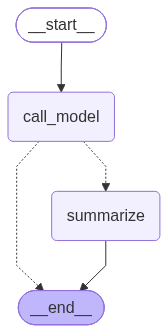

In [10]:
from typing import Literal
from langchain_core.messages import SystemMessage, HumanMessage, RemoveMessage

class SummaryState(MessagesState):
    summary: str

def call_model(state: SummaryState):
    msgs = state["messages"]
    if state.get("summary"):
        msgs = [SystemMessage(f"Summary of the earlier conversation: {state['summary']}")] + msgs
    return {"messages": [llm.invoke(msgs)]}

def should_summarize(state: SummaryState) -> Literal["summarize", "__end__"]:
    return "summarize" if len(state["messages"]) > 4 else END

def summarize(state: SummaryState):
    prompt = (f"Existing summary: {state.get('summary', 'none')}\n"
              "Extend the summary with the new messages above. Keep every personal fact. 2-3 sentences.")
    summary = llm.invoke(state["messages"] + [HumanMessage(prompt)]).text
    delete = [RemoveMessage(id=m.id) for m in state["messages"][:-2]]   # keep last 2
    print("   📝 summarized & removed", len(delete), "messages")
    return {"summary": summary, "messages": delete}

b = StateGraph(SummaryState)
b.add_node(call_model); b.add_node(summarize)
b.add_edge(START, "call_model")
b.add_conditional_edges("call_model", should_summarize)
b.add_edge("summarize", END)
summary_graph = b.compile(checkpointer=InMemorySaver())
show_graph(summary_graph)

In [11]:
cfg = {"configurable": {"thread_id": "summary-demo"}}
for text in ["My favourite colour is green. Reply OK.", "I live in Pune. Reply OK.",
             "I work as a data engineer. Reply OK.", "What's my favourite colour and city?"]:
    out = summary_graph.invoke({"messages": [("user", text)]}, cfg)
    print("🧑", text, "\n🤖", out["messages"][-1].text)

print("\nSummary in state:", summary_graph.get_state(cfg).values["summary"])

🧑 My favourite colour is green. Reply OK. 
🤖 OK


🧑 I live in Pune. Reply OK. 
🤖 OK


   📝 summarized & removed 4 messages
🧑 I work as a data engineer. Reply OK. 
🤖 OK


🧑 What's my favourite colour and city? 
🤖 Your favourite colour is **green**. You haven't mentioned a favourite city, but you **live in Pune**.

Summary in state: The user's favourite colour is green, and they live in Pune. They work as a data engineer.


## ✅ Recap
* `compile(checkpointer=...)` + `{"configurable": {"thread_id": ...}}` = conversation memory.
* `get_state` / `get_state_history` let you inspect every checkpoint.
* `InMemorySaver` for demos, `SqliteSaver`/`PostgresSaver` for persistence.
* Control context size by **trimming** (simple) or **summarizing + `RemoveMessage`** (keeps facts).